In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
import os
print("Current Working Directory:", os.getcwd())


Current Working Directory: c:\Users\LENOVO\OneDrive\Desktop\Ecommerce-Sales-Analytics\notebook


In [9]:
df = pd.read_csv(
    "../data/Sample - Superstore.csv",
    encoding="cp1252"
)
print("Dataset Shape:", df.shape)


Dataset Shape: (9994, 21)


In [10]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [12]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [13]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [16]:
print(df.dtypes)

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


In [17]:
print("Duplicate Rows:", df.duplicated().sum())
print("Negative Sales:", (df["Sales"] < 0).sum())
print("Zero Sales:", (df["Sales"] == 0).sum())
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())
print("Negative Profit:", (df["Profit"] < 0).sum())

Duplicate Rows: 0
Negative Sales: 0
Zero Sales: 0
Negative Quantity: 0
Zero Quantity: 0
Negative Profit: 1871


In [18]:
kpis = {
    "Total Sales": df["Sales"].sum(),
    "Total Profit": df["Profit"].sum(),
    "Total Orders": df["Order ID"].nunique(),
    "Total Customers": df["Customer ID"].nunique(),
    "Total Products": df["Product ID"].nunique(),
    "Profit Margin": df["Profit"].sum() / df["Sales"].sum()
}

kpis

{'Total Sales': np.float64(2297200.8603),
 'Total Profit': np.float64(286397.0217),
 'Total Orders': 5009,
 'Total Customers': 793,
 'Total Products': 1862,
 'Profit Margin': np.float64(0.12467217240315605)}

In [19]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month_Name"] = df["Order Date"].dt.strftime("%b")
df["Quarter"] = df["Order Date"].dt.quarter

In [20]:
# Group by Category and calculate Sales, Profit, and Profit Margin
category_summary = (
    df.groupby("Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Profit_Margin_Percent=("Profit", lambda x: round(x.sum() / df.loc[x.index, "Sales"].sum() * 100, 2))
      )
      .reset_index()
      .sort_values("Total_Profit", ascending=True)
)

print(category_summary)


          Category  Total_Sales  Total_Profit  Profit_Margin_Percent
0        Furniture  741999.7953    18451.2728                   2.49
1  Office Supplies  719047.0320   122490.8008                  17.04
2       Technology  836154.0330   145454.9481                  17.40


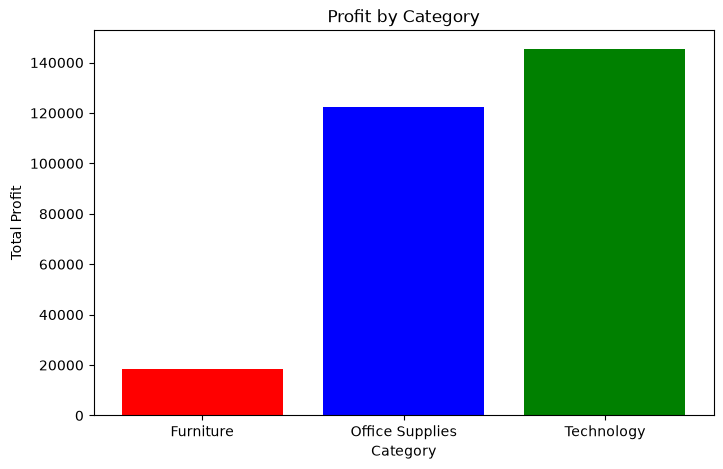

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(category_summary["Category"], category_summary["Total_Profit"], color=["red","blue","green"])
plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.show()


In [22]:
# Group by Sub-Category and calculate Sales, Profit, Discount, and Profit Margin
subcat_summary = (
    df.groupby("Sub-Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Average_Discount=("Discount", "mean"),
          Profit_Margin_Percent=("Profit", lambda x: round(x.sum() / df.loc[x.index, "Sales"].sum() * 100, 2))
      )
      .reset_index()
      .sort_values("Total_Profit", ascending=True)
)

print(subcat_summary)


   Sub-Category  Total_Sales  Total_Profit  Average_Discount  \
16       Tables  206965.5320   -17725.4811          0.261285   
4     Bookcases  114879.9963    -3472.5560          0.211140   
15     Supplies   46673.5380    -1189.0995          0.076842   
8     Fasteners    3024.2800      949.5182          0.082028   
11     Machines  189238.6310     3384.7569          0.306087   
10       Labels   12486.3120     5546.2540          0.068681   
2           Art   27118.7920     6527.7870          0.074874   
7     Envelopes   16476.4020     6964.1767          0.080315   
9   Furnishings   91705.1640    13059.1436          0.138349   
1    Appliances  107532.1610    18138.0054          0.166524   
14      Storage  223843.6080    21278.8264          0.074704   
5        Chairs  328449.1030    26590.1663          0.170178   
3       Binders  203412.7330    30221.7633          0.372292   
12        Paper   78479.2060    34053.5693          0.074891   
0   Accessories  167380.3180    41936.63

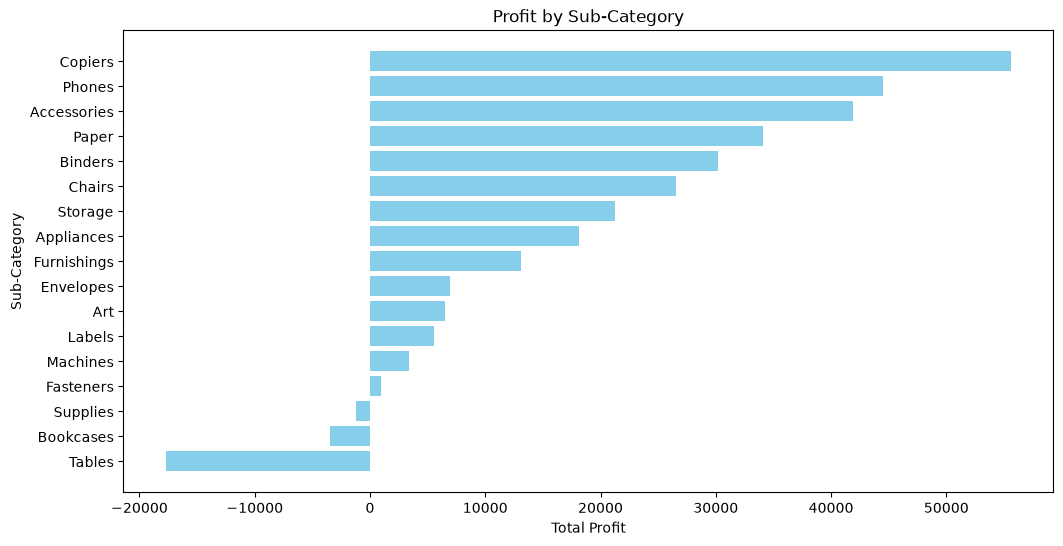

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.barh(subcat_summary["Sub-Category"], subcat_summary["Total_Profit"], color="skyblue")
plt.title("Profit by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.show()


In [24]:
# Group by Product Name and calculate Sales, Profit, Discount, and Profit Margin
product_profitability = (
    df.groupby("Product Name")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Average_Discount=("Discount", "mean"),
          Profit_Margin_Percent=("Profit", lambda x: round(x.sum() / df.loc[x.index, "Sales"].sum() * 100, 2))
      )
      .reset_index()
      .sort_values("Total_Profit", ascending=True)
)

print(product_profitability.head(10))  # show worst 10 products


                                           Product Name  Total_Sales  \
475           Cubify CubeX 3D Printer Double Head Print    11099.963   
985           Lexmark MX611dhe Monochrome Laser Printer    16829.901   
476           Cubify CubeX 3D Printer Triple Head Print     7999.980   
425   Chromcraft Bull-Nose Wood Oval Conference Tabl...     9917.640   
376   Bush Advantage Collection Racetrack Conference...     9544.725   
683           GBC DocuBind P400 Electric Binding System    17965.068   
444   Cisco TelePresence System EX90 Videoconferenci...    22638.480   
1043  Martin Yale Chadless Opener Electric Letter Op...    16656.200   
285                        Balt Solid Wood Round Tables     6518.754   
364   BoxOffice By Design Rectangular and Half-Moon ...     1706.250   

      Total_Profit  Average_Discount  Profit_Margin_Percent  
475     -8879.9704          0.533333                 -80.00  
985     -4589.9730          0.400000                 -27.27  
476     -3839.9904   

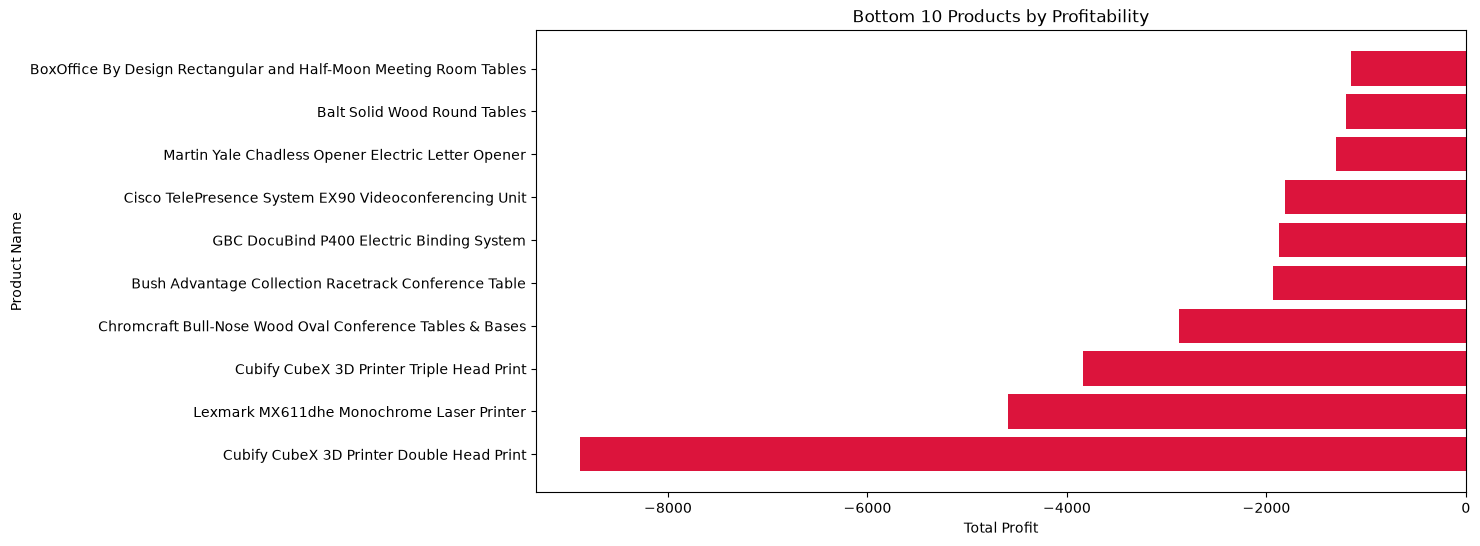

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.barh(product_profitability["Product Name"].head(10), 
         product_profitability["Total_Profit"].head(10), 
         color="crimson")
plt.title("Bottom 10 Products by Profitability")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")
plt.show()


In [26]:
product_summary = (
    df.groupby(["Product ID", "Product Name"])
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Avg_Discount=("Discount", "mean")
      )
      .reset_index()
)

loss_making_products = product_summary[
    (product_summary["Sales"] > 1000) &
    (product_summary["Profit"] < 0)
].sort_values("Profit")

loss_making_products.head(20)

,Product ID,Product Name,Sales,Profit,Quantity,Avg_Discount
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,11099.9630,-8879.9704,9,0.533333
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,16829.9010,-4589.9730,18,0.400000
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,7999.9800,-3839.9904,4,0.500000
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.6400,-2876.1156,27,0.280000
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,9544.7250,-1934.3976,33,0.350000
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.0680,-1878.1662,27,0.450000
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.4800,-1811.0784,6,0.500000
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,16656.2000,-1299.1836,22,0.100000
346,FUR-TA-10001950,Balt Solid Wood Round Tables,6518.7540,-1201.0581,19,0.200000
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,1706.2500,-1148.4375,15,0.483333


In [27]:
df["Discount_Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.10, 0.20, 0.30, 0.50, 1],
    labels=[
        "0%",
        "1-10%",
        "11-20%",
        "21-30%",
        "31-50%",
        "50%+"
    ]
)

In [28]:
discount_analysis = (
    df.groupby("Discount_Band", observed=True)
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .reset_index()
)

discount_analysis["Profit_Margin"] = (
    discount_analysis["Profit"] /
    discount_analysis["Sales"]
)

discount_analysis

,Discount_Band,Sales,Profit,Orders,Profit_Margin
0,0%,1.087908e+06,320987.6032,2644,0.295050
1,1-10%,5.436935e+04,9029.1770,89,0.166071
2,11-20%,7.921529e+05,91756.2975,2436,0.115832
3,21-30%,1.032267e+05,-10369.2774,211,-0.100452
4,31-50%,1.953148e+05,-48447.7273,280,-0.248049
5,50%+,6.422874e+04,-76559.0513,685,-1.191975


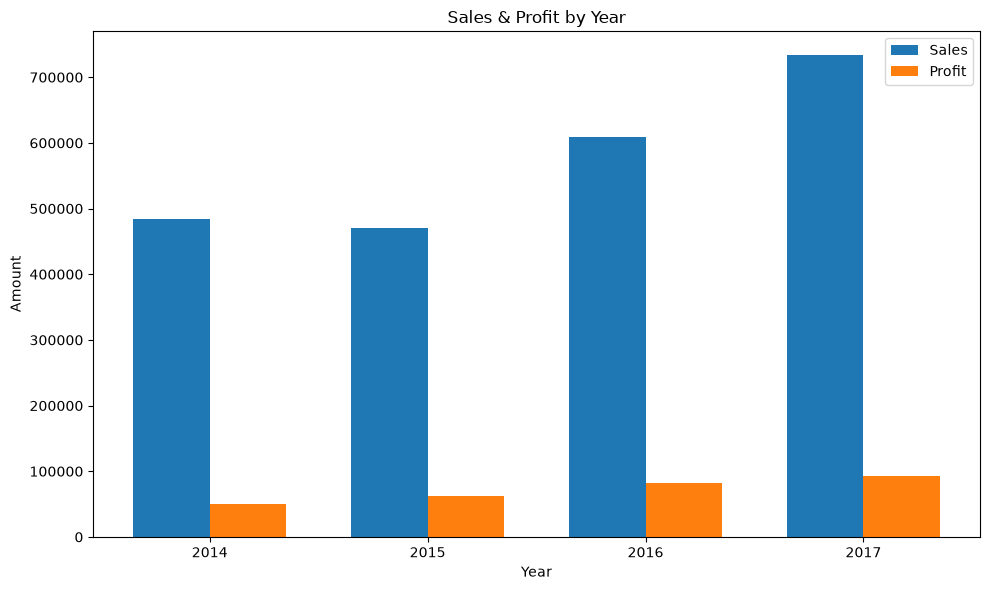

In [29]:
yearly = (
    df.groupby("Year")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

x = np.arange(len(yearly))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, yearly["Sales"], width, label="Sales")
plt.bar(x + width/2, yearly["Profit"], width, label="Profit")

plt.xticks(x, yearly["Year"])
plt.xlabel("Year")
plt.ylabel("Amount")
plt.title("Sales & Profit by Year")
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly_sales = (
    df.groupby("Month")
      .agg(Sales=("Sales", "sum"))
      .reset_index()
)

monthly_sales["Month"] = monthly_sales["Month"].astype(str)

monthly_sales.head()

,Month,Sales
0,2014-01,14236.895
1,2014-02,4519.892
2,2014-03,55691.009
3,2014-04,28295.345
4,2014-05,23648.287


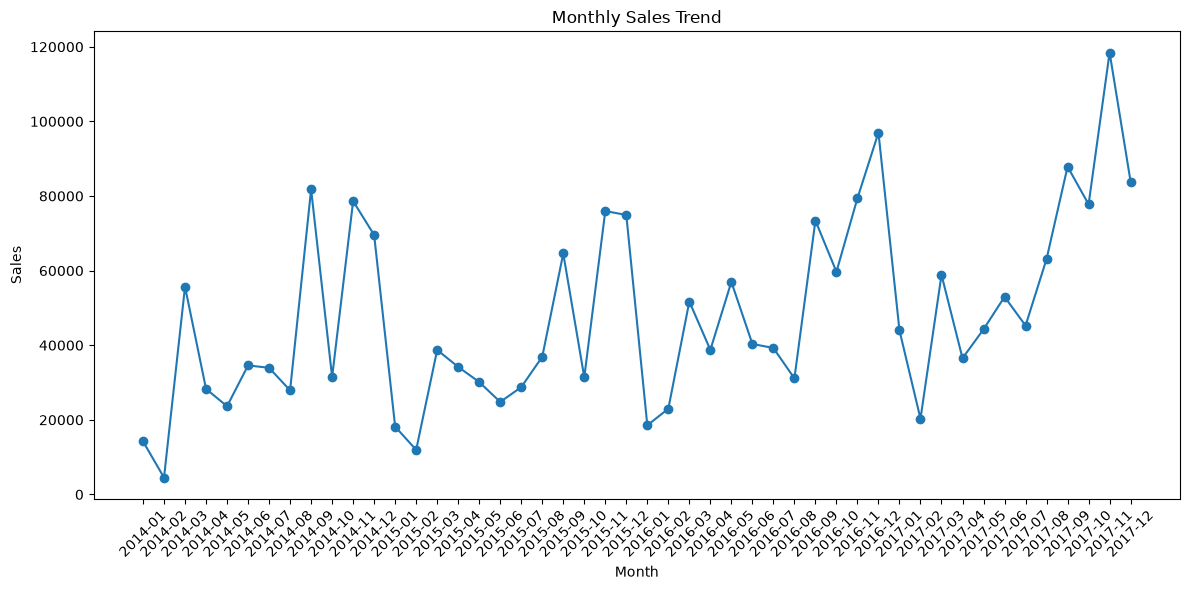

In [31]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Monthly Sales Trend")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
category_summary = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

category_summary

,Category,Sales,Profit
0,Furniture,741999.7953,18451.2728
1,Office Supplies,719047.0320,122490.8008
2,Technology,836154.0330,145454.9481


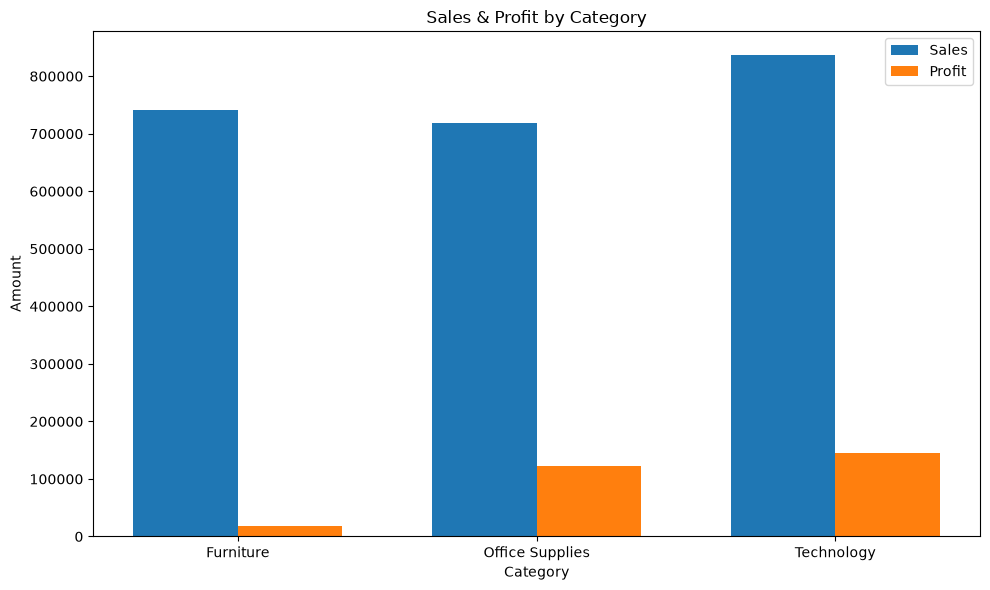

In [33]:
x = np.arange(len(category_summary))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    category_summary["Sales"],
    width,
    label="Sales"
)

plt.bar(
    x + width/2,
    category_summary["Profit"],
    width,
    label="Profit"
)

plt.xticks(x, category_summary["Category"])
plt.xlabel("Category")
plt.ylabel("Amount")
plt.title("Sales & Profit by Category")
plt.legend()

plt.tight_layout()
plt.show()

In [34]:
subcategory_profit = (
    df.groupby("Sub-Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
      .sort_values("Profit")
)

subcategory_profit

,Sub-Category,Sales,Profit
16,Tables,206965.5320,-17725.4811
4,Bookcases,114879.9963,-3472.5560
15,Supplies,46673.5380,-1189.0995
8,Fasteners,3024.2800,949.5182
11,Machines,189238.6310,3384.7569
10,Labels,12486.3120,5546.2540
2,Art,27118.7920,6527.7870
7,Envelopes,16476.4020,6964.1767
9,Furnishings,91705.1640,13059.1436
1,Appliances,107532.1610,18138.0054


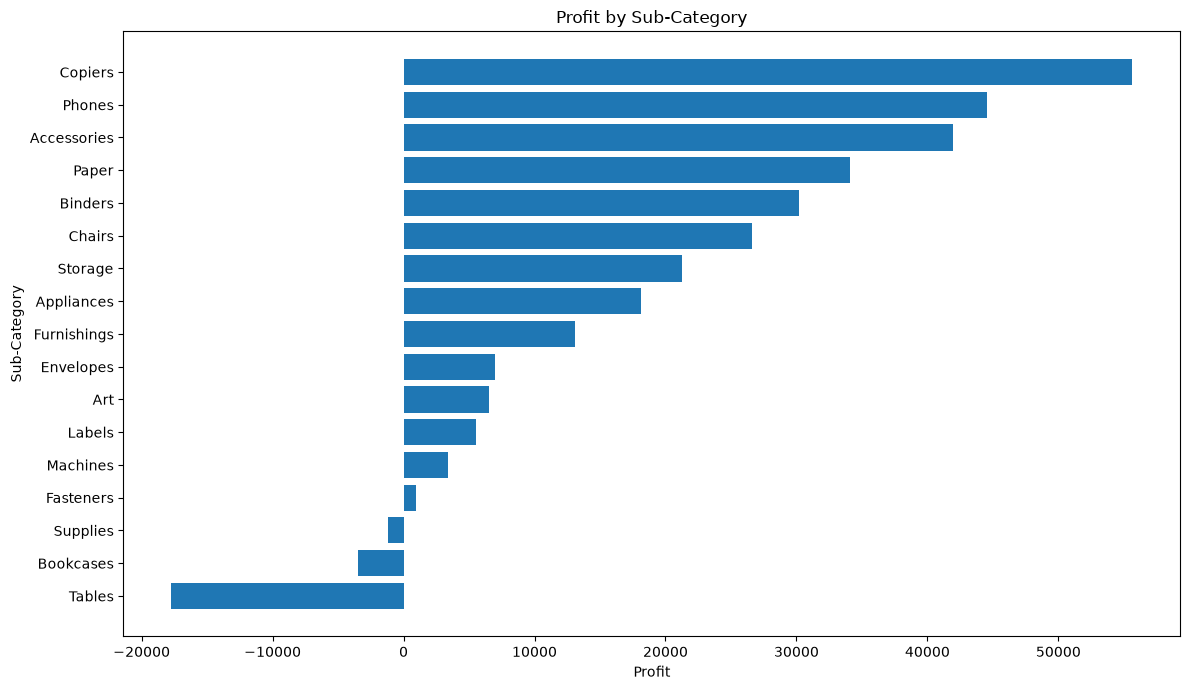

In [35]:
plt.figure(figsize=(12, 7))

plt.barh(
    subcategory_profit["Sub-Category"],
    subcategory_profit["Profit"]
)

plt.xlabel("Profit")
plt.ylabel("Sub-Category")
plt.title("Profit by Sub-Category")

plt.tight_layout()
plt.show()

In [36]:
region_summary = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

region_summary

,Region,Sales,Profit
0,Central,501239.8908,39706.3625
1,East,678781.2400,91522.7800
2,South,391721.9050,46749.4303
3,West,725457.8245,108418.4489


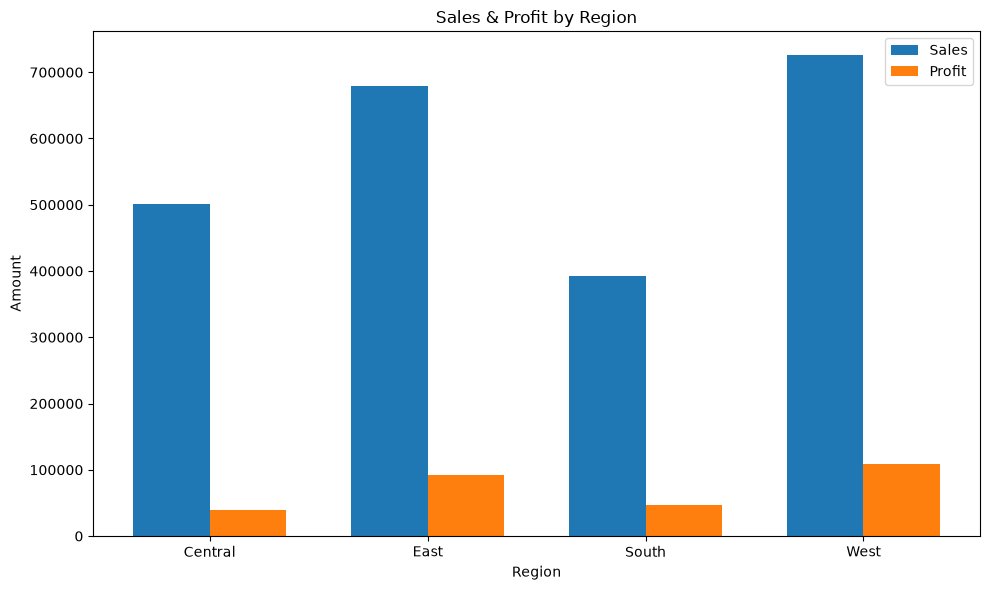

In [37]:
x = np.arange(len(region_summary))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    region_summary["Sales"],
    width,
    label="Sales"
)

plt.bar(
    x + width/2,
    region_summary["Profit"],
    width,
    label="Profit"
)

plt.xticks(x, region_summary["Region"])
plt.xlabel("Region")
plt.ylabel("Amount")
plt.title("Sales & Profit by Region")
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
df["Discount_Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.10, 0.20, 0.30, 0.50, 1],
    labels=[
        "0%",
        "1-10%",
        "11-20%",
        "21-30%",
        "31-50%",
        "50%+"
    ]
)

In [39]:
discount_analysis = (
    df.groupby("Discount_Band", observed=True)
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .reset_index()
)

discount_analysis["Profit_Margin"] = (
    discount_analysis["Profit"] /
    discount_analysis["Sales"]
)

discount_analysis

,Discount_Band,Sales,Profit,Orders,Profit_Margin
0,0%,1.087908e+06,320987.6032,2644,0.295050
1,1-10%,5.436935e+04,9029.1770,89,0.166071
2,11-20%,7.921529e+05,91756.2975,2436,0.115832
3,21-30%,1.032267e+05,-10369.2774,211,-0.100452
4,31-50%,1.953148e+05,-48447.7273,280,-0.248049
5,50%+,6.422874e+04,-76559.0513,685,-1.191975


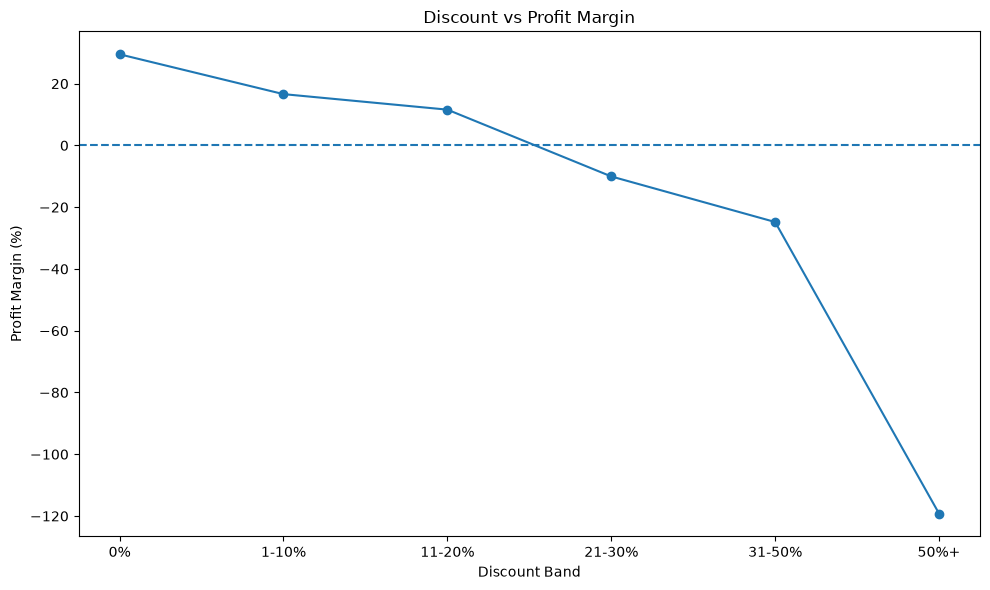

In [40]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_analysis["Discount_Band"],
    discount_analysis["Profit_Margin"] * 100,
    marker="o"
)

plt.xlabel("Discount Band")
plt.ylabel("Profit Margin (%)")
plt.title("Discount vs Profit Margin")

plt.axhline(0, linestyle="--")

plt.tight_layout()
plt.show()

In [41]:
product_sales = (
    df.groupby(["Product ID", "Product Name"])
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .reset_index()
)

In [42]:
top10_products = (
    product_sales
    .sort_values("Sales", ascending=False)
    .head(10)
)

top10_products

,Product ID,Product Name,Sales,Profit,Quantity
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7.753039e+03,31
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1.811078e+03,6
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14,39
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,4.094977e+03,12
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27
1443,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,17030.312,-2.620048e+02,11


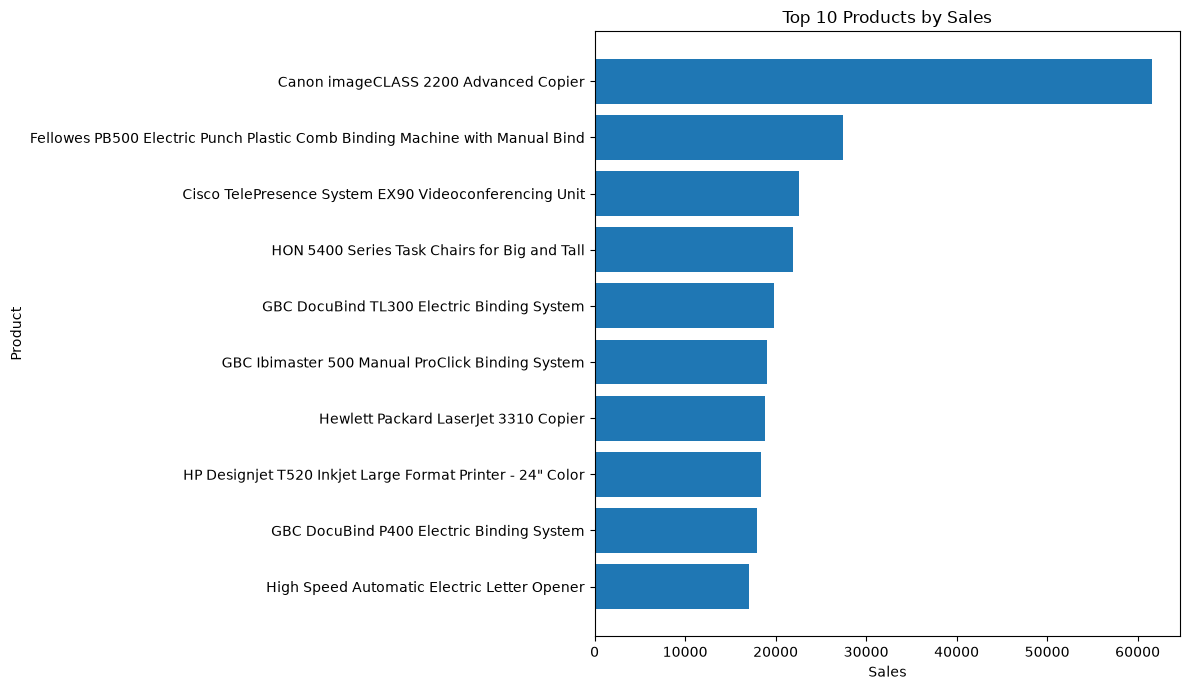

In [43]:
plt.figure(figsize=(12, 7))

plt.barh(
    top10_products["Product Name"],
    top10_products["Sales"]
)

plt.xlabel("Sales")
plt.ylabel("Product")
plt.title("Top 10 Products by Sales")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [44]:
loss_making_products = (
    product_summary[
        product_summary["Profit"] < 0
    ]
    .sort_values("Profit")
    .head(10)
)

loss_making_products

,Product ID,Product Name,Sales,Profit,Quantity,Avg_Discount
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9,0.533333
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18,0.400000
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4,0.500000
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.640,-2876.1156,27,0.280000
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,9544.725,-1934.3976,33,0.350000
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27,0.450000
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1811.0784,6,0.500000
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,16656.200,-1299.1836,22,0.100000
346,FUR-TA-10001950,Balt Solid Wood Round Tables,6518.754,-1201.0581,19,0.200000
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,1706.250,-1148.4375,15,0.483333


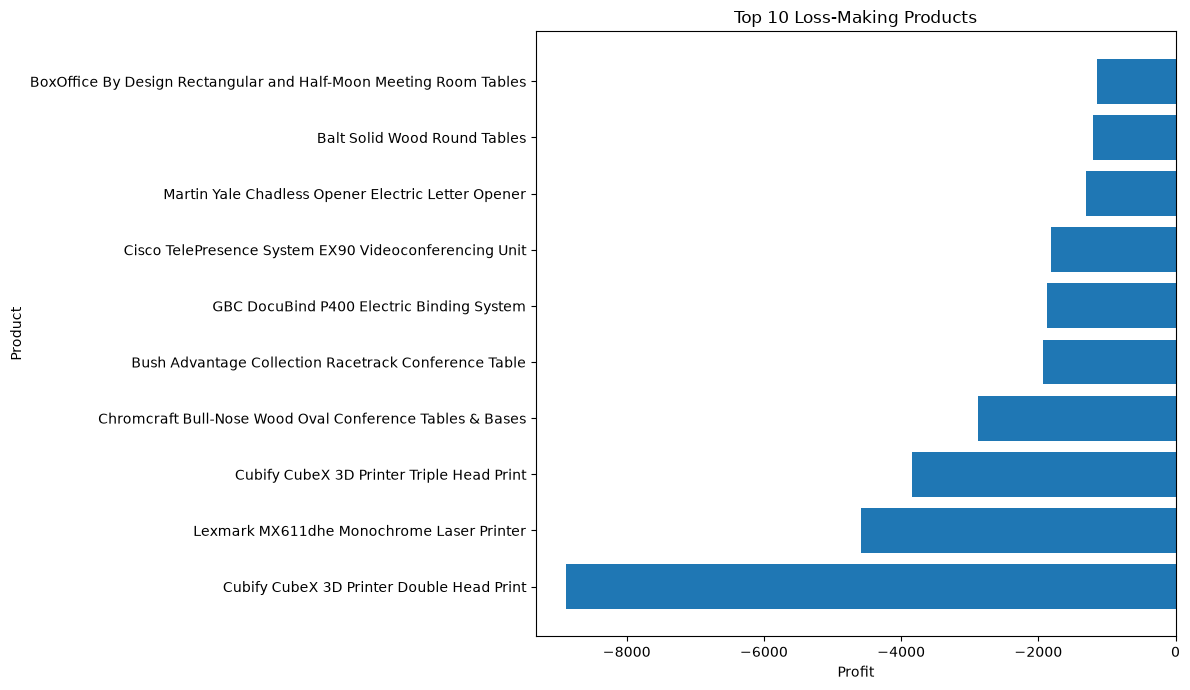

In [45]:
plt.figure(figsize=(12, 7))

plt.barh(
    loss_making_products["Product Name"],
    loss_making_products["Profit"]
)

plt.xlabel("Profit")
plt.ylabel("Product")
plt.title("Top 10 Loss-Making Products")

plt.tight_layout()
plt.show()